# Mapa de proveedores y productos en CISA KEV

## Resumen

**Decisión:** identificar concentraciones del catálogo para orientar el cruce posterior con un inventario propio. La red se construye a partir de relaciones proveedor-producto reportadas; no representa rutas de ataque, conectividad de activos ni propagación.

**Resultado del corte:** El snapshot contiene 1.779 CVE, 751 pares proveedor-producto y 294 proveedores declarados.

## Contexto y método

Comparación descriptiva para apoyar preguntas de gestión. No se identifica causalidad ni se valida un modelo productivo.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})

## Datos y procedencia

Fuente primaria: [CISA KEV](https://www.cisa.gov/known-exploited-vulnerabilities-catalog), snapshot CSV del 12-11-2026 con SHA-256 `85f484aba48c592c113722cb3e17e768fb5bd2f8f8ee7c548a2ed471e44efb85`. Un CVE es una entrada catalogada, no un incidente o pérdida. Los nombres se agregan tal como figuran, sin resolver alias comerciales.

In [2]:
path=repo / '03-financial-risk/05-enterprise-risk-advisory/04-cyber-ai/technology-change/data/cisa_kev_2026-11-12.csv'
assert hashlib.sha256(path.read_bytes()).hexdigest() == '85f484aba48c592c113722cb3e17e768fb5bd2f8f8ee7c548a2ed471e44efb85'
df=pd.read_csv(path)
assert df.cveID.is_unique
pairs=df.groupby(['vendorProject','product'],dropna=False).agg(cve=('cveID','nunique')).reset_index()
vendors=df.groupby('vendorProject',dropna=False).agg(cve=('cveID','nunique'),productos=('product','nunique')).sort_values('cve',ascending=False)
print('CVE:',len(df),'| pares proveedor-producto:',len(pairs),'| proveedores:',len(vendors))
display(vendors.head(10))

CVE: 1779 | pares proveedor-producto: 751 | proveedores: 294


,cve,productos
vendorProject,,
Microsoft,391,72
Cisco,103,45
Apple,96,9
Adobe,83,14
Google,77,26
Oracle,46,17
Apache,41,21
Ivanti,38,16
Fortinet,32,10


## Resultados

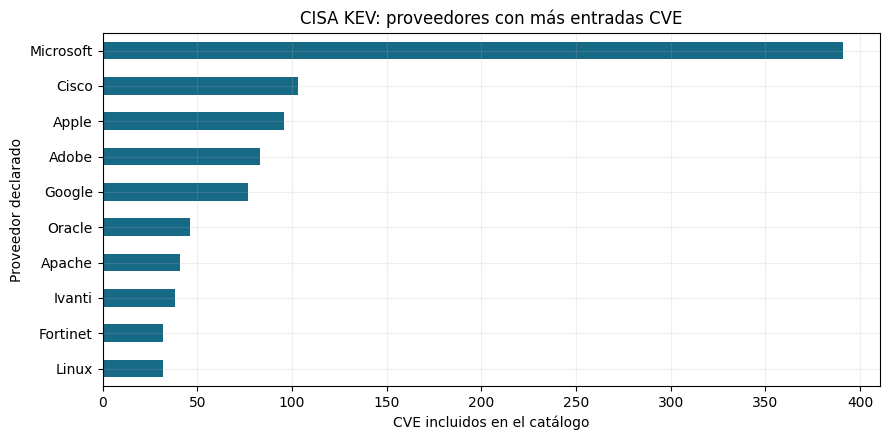

In [3]:
top=vendors.head(10).sort_values('cve'); ax=top.cve.plot.barh(color='#176a86'); ax.set(title='CISA KEV: proveedores con más entradas CVE',xlabel='CVE incluidos en el catálogo',ylabel='Proveedor declarado'); plt.tight_layout(); plt.show()

### Concentración y calidad de nombres

Se cuentan CVE únicos por proveedor declarado, sin normalizar alias. Los proveedores representan etiquetas del catálogo y no necesariamente entidades económicas únicas.

Proveedor vacío: 0 | producto vacío: 0
Participación de los cinco proveedores con más entradas: 42.2% del catálogo
CVE contabilizados por proveedor: 1779 | filas del catálogo: 1779


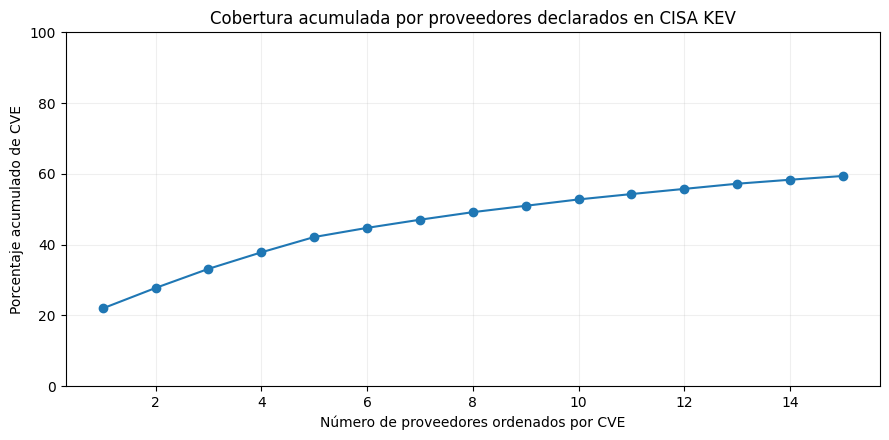

In [4]:
assert df.cveID.notna().all() and df.cveID.is_unique
missing_vendor=df.vendorProject.isna() | df.vendorProject.astype('string').str.strip().eq('')
missing_product=df['product'].isna() | df['product'].astype('string').str.strip().eq('')
print('Proveedor vacío:',int(missing_vendor.sum()),'| producto vacío:',int(missing_product.sum()))
print('Participación de los cinco proveedores con más entradas:',f'{100*vendors.cve.head(5).sum()/len(df):.1f}% del catálogo')
print('CVE contabilizados por proveedor:',int(vendors.cve.sum()),'| filas del catálogo:',len(df))
assert vendors.cve.sum() == len(df)
acumulado=vendors.cve.head(15).cumsum().div(len(df)).mul(100).reset_index(drop=True); acumulado.index=range(1,len(acumulado)+1)
ax=acumulado.plot(marker='o',title='Cobertura acumulada por proveedores declarados en CISA KEV');ax.set(xlabel='Número de proveedores ordenados por CVE',ylabel='Porcentaje acumulado de CVE',ylim=(0,100));plt.tight_layout();plt.show()

La concentración es la del catálogo de vulnerabilidades conocidas explotadas, afectada por criterios de inclusión y etiquetas. No mide cuota de mercado, exposición de la organización ni rutas de ataque.

## Variante: concentración del catálogo y comparación de granularidades

Se calcula la suma de participaciones al cuadrado (HHI entre 0 y 1), tanto por proveedor declarado como por par proveedor-producto. Cada fila representa un CVE del snapshot, y cada agrupación asigna cada fila a una sola etiqueta declarada; diferencias de escritura y agrupaciones de productos pueden sesgar el resultado. Este HHI describe concentración de registros del catálogo, no dependencia empresarial ni probabilidad de compromiso. [NIST IR 8272](https://www.nist.gov/publications/impact-analysis-tool-interdependent-cyber-supply-chain-risks) estudia el impacto de dependencias en una cadena y exige contexto de nodos propios; [NIST IR 8276](https://csrc.nist.gov/pubs/ir/8276/final) aborda gestión de proveedores.

In [5]:
counts_vendor=vendors.cve
counts_pair=pairs.cve
assert counts_vendor.sum()==len(df) and counts_pair.sum()==len(df)
concentracion=pd.DataFrame([{'granularidad':'Proveedor declarado','grupos':len(counts_vendor),'hhi_0_a_1':((counts_vendor/len(df))**2).sum()}, {'granularidad':'Par proveedor-producto declarado','grupos':len(counts_pair),'hhi_0_a_1':((counts_pair/len(df))**2).sum()}])
concentracion['numero_efectivo']=1/concentracion.hhi_0_a_1
assert concentracion.hhi_0_a_1.between(0,1).all()
display(concentracion.round(4))
print('La diferencia refleja la granularidad de la etiqueta, no una reducción causal del riesgo.')

,granularidad,grupos,hhi_0_a_1,numero_efectivo
0,Proveedor declarado,294,0.0631,15.8379
1,Par proveedor-producto declarado,751,0.0142,70.5886


La diferencia refleja la granularidad de la etiqueta, no una reducción causal del riesgo.


## Interpretación y límites

Las aristas proveedor-producto describen el catálogo, no dependencia técnica entre activos. No se infieren rutas, criticidad de red o probabilidad de intrusión; para ello se requieren inventario, topología, permisos y validación de exposición.

**Reproducción:** desde este repositorio ejecutar `python -m jupyter nbconvert --execute --to notebook --inplace 01_cisa_vendor_productos.ipynb` en la carpeta del proyecto; requiere Python, pandas, matplotlib, nbformat, nbclient e ipykernel.